# Exercise 2 - Classification Task
# Created by: Sean Matthew Rosales Parabuac (ID:639264)

# Loading Libraries & Connecting With Data

In [43]:
#Please note that I am running four Classification algorithms
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

#This is for feature scaling in data preprocessing
from sklearn.preprocessing import StandardScaler

#This is the first algorithm
from sklearn.linear_model import LogisticRegression
#Second algorithm chosen is Decision Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree 
#The third is Random Forest
from sklearn.ensemble import RandomForestClassifier
#Last is KNeighbors
from sklearn.neighbors import KNeighborsClassifier

#It is explained in the reflection why I chose four algorithms

#Note that the imports below are for the general purpose of what's in the requirements of the task
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score
from sklearn.metrics import accuracy_score, confusion_matrix

data = pd.read_csv("/kaggle/input/datasets/seanparabuac/breast-cancer-wisconsin/data.csv")
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [44]:
data.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [45]:
data.shape

(569, 33)

In [46]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [47]:
data.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [48]:
data.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

diagnosis
B    357
M    212
Name: count, dtype: int64


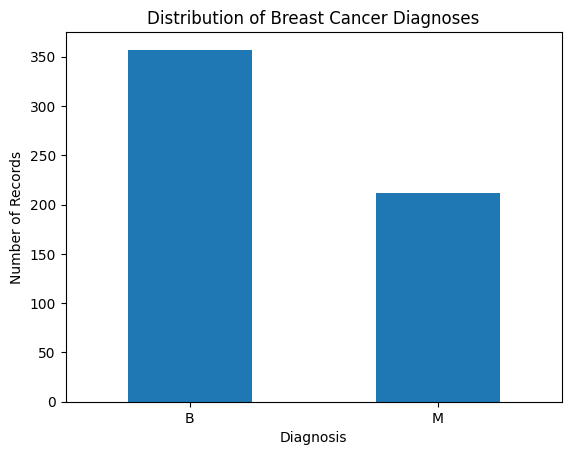

In [49]:
#This cell is looking for the class imbalance
#The two classes are Benign diagnoses and Malignant diagnoses
diagnosisCounts = data["diagnosis"].value_counts()

print(diagnosisCounts)

diagnosisCounts.plot(kind="bar")

plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

# Data Preprocessing & Separation

In [50]:
#Removing unneeded columns.
#I passed the dataset to ChatGPT, and it found that the 32nd column was empty in the unedited dataset
#Therefore, I removed it alongside the ID column for each record
data = data.drop(columns=["id", "Unnamed: 32"])

print(data.shape)
data.head()

(569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [51]:
#Checking the final count of Benign and Malignant records
data["diagnosis"] = data["diagnosis"].map({"B": 0,"M": 1})

print(data["diagnosis"].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [52]:
X = data.drop(columns = ["diagnosis"])
y = data["diagnosis"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [53]:
XTrain, XTest, yTrain, yTest = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

#Double checking if the 80:20 split of data is correct
print("Training Records:", XTrain.shape[0])
print("Testing Records:", XTest.shape[0])
print(XTest.head())

Training Records: 455
Testing Records: 114
     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
120        11.41         10.82           73.34      403.3          0.09373   
250        20.94         23.56          138.90     1364.0          0.10070   
375        16.17         16.07          106.30      788.5          0.09880   
99         14.42         19.77           94.48      642.5          0.09752   
455        13.38         30.72           86.34      557.2          0.09245   

     compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
120           0.06685         0.03512              0.02623         0.1667   
250           0.16060         0.27120              0.13100         0.2205   
375           0.14380         0.06651              0.05397         0.1990   
99            0.11410         0.09388              0.05839         0.1879   
455           0.07426         0.02819              0.03264         0.1375   

     fractal_dimension_me

In [54]:
#This cell initiates feature scaling
#This is important for the algorithms later
scaler = StandardScaler()

XTrainScaled = scaler.fit_transform(XTrain)
XTestScaled = scaler.transform(XTest)

# Model Training & Testing

In [55]:
logisticModel = LogisticRegression(max_iter=1000)

#Needs to use the rescaled data due to errors faced in the visualizations
logisticModel.fit(XTrainScaled, yTrain)

LogisticRegression(max_iter=1000)

In [56]:
decisionTreeModel = DecisionTreeClassifier(random_state=42)

decisionTreeModel.fit(XTrain, yTrain)

DecisionTreeClassifier(random_state=42)

In [57]:
randomForestModel = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

randomForestModel.fit(XTrain, yTrain)

RandomForestClassifier(random_state=42)

In [58]:
kNeighborModel = KNeighborsClassifier(n_neighbors=5)

#Same as logistic regression using rescaled data
kNeighborModel.fit(XTrainScaled, yTrain)

KNeighborsClassifier()

In [59]:
# Logistic Regression Feature Coefficient Analysis

logisticCoefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logisticModel.coef_[0]
})

#Calculating absolute coefficient values for ranking
logisticCoefficients["Absolute Coefficient"] = (
    logisticCoefficients["Coefficient"].abs()
)

#Sorting features based on their coefficient strength
logisticCoefficients = logisticCoefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("Top 10 Logistic Regression Features:")
print(logisticCoefficients.head(10))

Top 10 Logistic Regression Features:
                Feature  Coefficient  Absolute Coefficient
21        texture_worst     1.434093              1.434093
10            radius_se     1.233325              1.233325
28       symmetry_worst     1.061264              1.061264
7   concave points_mean     0.952813              0.952813
26      concavity_worst     0.911406              0.911406
13              area_se     0.909029              0.909029
15       compactness_se    -0.906925              0.906925
23           area_worst     0.900477              0.900477
20         radius_worst     0.896968              0.896968
6        concavity_mean     0.782298              0.782298


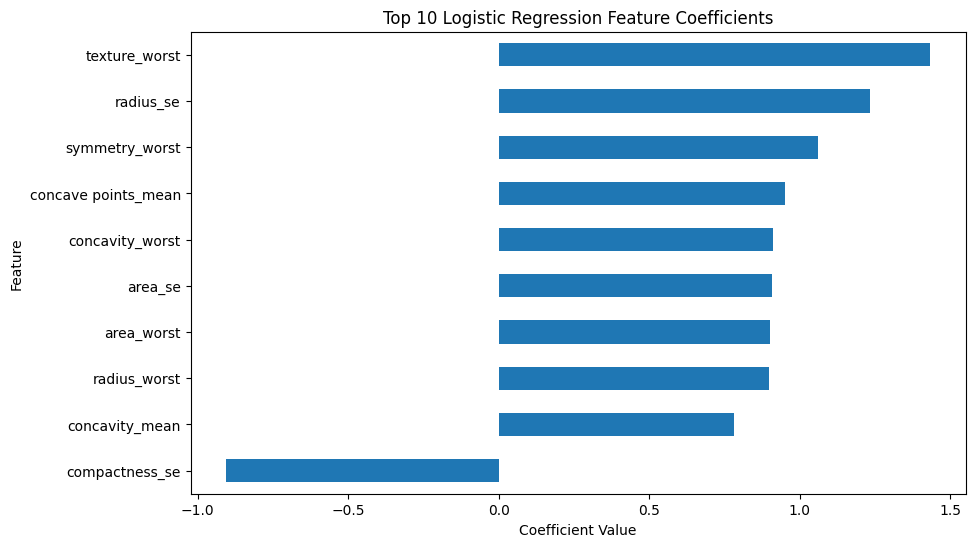

In [60]:
#A showcase of feature coefficients for specifically Logistic Regression
#This chart was recommended by ChatGPT for the algorithm's validations

logisticTopFeatures = logisticCoefficients.head(10)

logisticTopFeatures.sort_values(
    by="Coefficient"
).plot(kind="barh",x="Feature",y="Coefficient",legend=False,figsize=(10, 6))

plt.title("Top 10 Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.show()

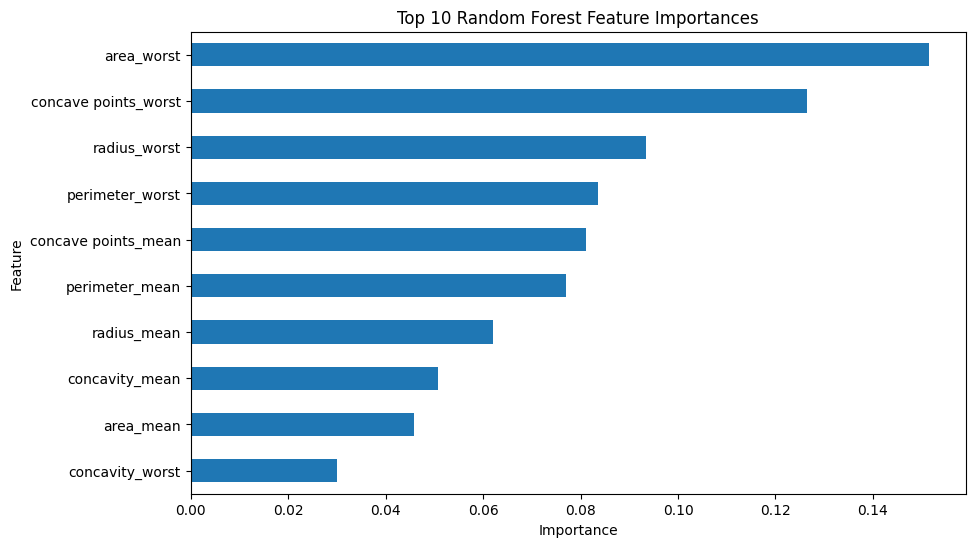

In [85]:
#Showcasing what Random Forest used in the decision making
#Decision trees shown in Visualization later rely on the feature importance
#Random Forest regarded these features as higher to lower importance to showcase decisions

randomForestImportance = pd.Series(
    randomForestModel.feature_importances_,
    index=X.columns
)

#Sorting features based on their importance
randomForestImportance = randomForestImportance.sort_values(ascending=False).head(10)

#Visualising the top 10 most important features
randomForestImportance.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


# Model Testing Predictions

Note that 0 means Benign and 1 means Malignant

In [61]:
logisticPrediction = logisticModel.predict(XTestScaled)

print("Predicted Diagnoses:")
print(logisticPrediction)

Predicted Diagnoses:
[0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


In [62]:
decisionTreePrediction = decisionTreeModel.predict(XTest)

print("Decision Tree Predictions:")
print(decisionTreePrediction)

Decision Tree Predictions:
[0 1 1 1 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 1 0 0 1 0 0 1 0 0 0 1 1 0 0 0 1 1 0
 0 1 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 1 1]


In [63]:
randomForestPrediction = randomForestModel.predict(XTest)

print("Random Forest Predictions:")
print(randomForestPrediction)

Random Forest Predictions:
[0 1 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 1 1]


In [64]:
kNeighborPrediction = kNeighborModel.predict(XTestScaled)

print("k-NN Predictions:")
print(kNeighborPrediction)

k-NN Predictions:
[0 1 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


# Model Evaluation

Please note that every evaluation type (Precision, Comparison, etc), will feature evaluations for EVERY algorithm in each cell.

In [65]:
#This cell evaluates Actual vs Predicted diagnoses

logisticComparison = pd.DataFrame({"Actual": yTest.values, "Predicted": logisticPrediction})

decisionTreeComparison = pd.DataFrame({"Actual": yTest.values, "Predicted": decisionTreePrediction})

randomForestComparison = pd.DataFrame({"Actual": yTest.values, "Predicted": randomForestPrediction})

kNeighborComparison = pd.DataFrame({"Actual": yTest.values, "Predicted": kNeighborPrediction})

print("Logistic Regression:", logisticComparison.head(5))
print("Decision Tree:", decisionTreeComparison.head(5))
print("Random Forest", randomForestComparison.head(5))
print("k-NN:", kNeighborComparison.head(5))

Logistic Regression:    Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          1
Decision Tree:    Actual  Predicted
0       0          0
1       1          1
2       0          1
3       1          1
4       0          0
Random Forest    Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
k-NN:    Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          0
4       0          0


In [66]:
#Model accuracy percentage check for each algorithm

logisticAccuracy = accuracy_score(yTest, logisticPrediction)
decisionTreeAccuracy = accuracy_score(yTest, decisionTreePrediction)
randomForestAccuracy = accuracy_score(yTest, randomForestPrediction)
kNeighborAccuracy = accuracy_score(yTest, kNeighborPrediction)

print("Logistic Regression Accuracy:", logisticAccuracy * 100, "%")
print("Decision Tree Accuracy:", decisionTreeAccuracy * 100, "%")
print("Random Forest Accuracy:", randomForestAccuracy * 100, "%")
print("k-NN Accuracy:", kNeighborAccuracy * 100, "%")

Logistic Regression Accuracy: 96.49122807017544 %
Decision Tree Accuracy: 92.98245614035088 %
Random Forest Accuracy: 97.36842105263158 %
k-NN Accuracy: 95.6140350877193 %


In [67]:
#Precision score as per assessment requirements, done for each algorithm

logisticPrecision = precision_score(yTest, logisticPrediction)
decisionTreePrecision = precision_score(yTest, decisionTreePrediction)
randomForestPrecision = precision_score(yTest, randomForestPrediction)
kNeighborPrecision = precision_score(yTest, kNeighborPrediction)

print("Precision")
print("Logistic Regression:", logisticPrecision)
print("Decision Tree:", decisionTreePrecision)
print("Random Forest:", randomForestPrecision)
print("k-NN:", kNeighborPrecision)

Precision
Logistic Regression: 0.975
Decision Tree: 0.9047619047619048
Random Forest: 1.0
k-NN: 0.9743589743589743


In [68]:
#The recall score for each algorithm
logisticRecall = recall_score(yTest, logisticPrediction)
decisionTreeRecall = recall_score(yTest, decisionTreePrediction)
randomForestRecall = recall_score(yTest, randomForestPrediction)
kNeighborRecall = recall_score(yTest, kNeighborPrediction)

print("Recall")
print("Logistic Regression:", logisticRecall)
print("Decision Tree:", decisionTreeRecall)
print("Random Forest:", randomForestRecall)
print("k-NN:", kNeighborRecall)

Recall
Logistic Regression: 0.9285714285714286
Decision Tree: 0.9047619047619048
Random Forest: 0.9285714285714286
k-NN: 0.9047619047619048


In [69]:
#F1-score for each algorithm
logisticF1 = f1_score(yTest, logisticPrediction)
decisionTreeF1 = f1_score(yTest, decisionTreePrediction)
randomForestF1 = f1_score(yTest, randomForestPrediction)
kNeighborF1 = f1_score(yTest, kNeighborPrediction)

print("F1-score")
print("Logistic Regression:", logisticF1)
print("Decision Tree:", decisionTreeF1)
print("Random Forest:", randomForestF1)
print("k-NN:", kNeighborF1)

F1-score
Logistic Regression: 0.9512195121951219
Decision Tree: 0.9047619047619048
Random Forest: 0.9629629629629629
k-NN: 0.9382716049382716


In [70]:
#The training data accuracy for each algorithm
logisticTrainAccuracy = accuracy_score(yTrain, logisticModel.predict(XTrainScaled))

decisionTreeTrainAccuracy = accuracy_score(yTrain, decisionTreeModel.predict(XTrain))

randomForestTrainAccuracy = accuracy_score(yTrain, randomForestModel.predict(XTrain))

kNeighborTrainAccuracy = accuracy_score(yTrain, kNeighborModel.predict(XTrainScaled))

print("Training Accuracy")
print("Logistic Regression:", logisticTrainAccuracy * 100, "%")
print("Decision Tree:", decisionTreeTrainAccuracy * 100, "%")
print("Random Forest:", randomForestTrainAccuracy * 100, "%")
print("KNN:", kNeighborTrainAccuracy * 100, "%")

Training Accuracy
Logistic Regression: 98.68131868131869 %
Decision Tree: 100.0 %
Random Forest: 100.0 %
KNN: 97.8021978021978 %


In [71]:
#Confusion matrix data for all algorithms
logisticMatrix = confusion_matrix(yTest, logisticPrediction)
decisionTreeMatrix = confusion_matrix(yTest, decisionTreePrediction)
randomForestMatrix = confusion_matrix(yTest, randomForestPrediction)
kNeighborMatrix = confusion_matrix(yTest, kNeighborPrediction)

print("Confusion Matrix")
print("Logistic Regression:", logisticMatrix)
print("Decision Tree:", decisionTreeMatrix)
print("Random Forest:", randomForestMatrix)
print("k-NN:", kNeighborMatrix)

Confusion Matrix
Logistic Regression: [[71  1]
 [ 3 39]]
Decision Tree: [[68  4]
 [ 4 38]]
Random Forest: [[72  0]
 [ 3 39]]
k-NN: [[71  1]
 [ 4 38]]


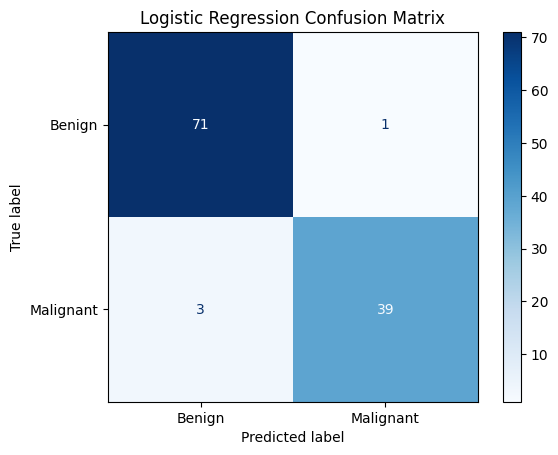

In [72]:
logisticDisplay = ConfusionMatrixDisplay(
    confusion_matrix = logisticMatrix,
    display_labels = ["Benign", "Malignant"]
)

logisticDisplay.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

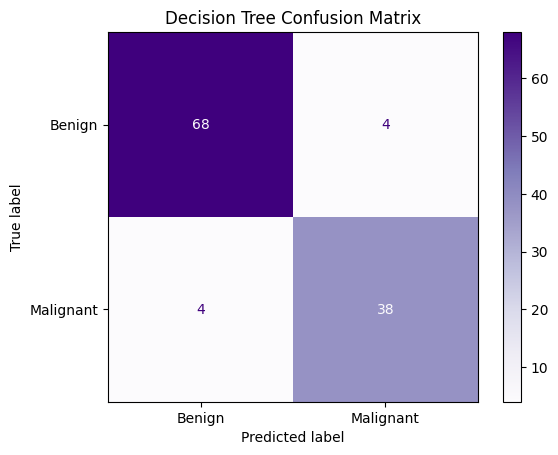

In [73]:
decisionTreeDisplay = ConfusionMatrixDisplay(
    confusion_matrix = decisionTreeMatrix,
    display_labels = ["Benign", "Malignant"]
)

decisionTreeDisplay.plot(cmap = "Purples")

plt.title("Decision Tree Confusion Matrix")
plt.show()

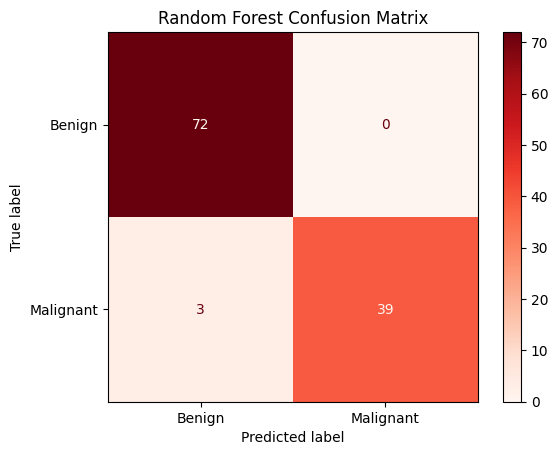

In [74]:
randomForestDisplay = ConfusionMatrixDisplay(
    confusion_matrix = randomForestMatrix,
    display_labels = ["Benign", "Malignant"]
)

randomForestDisplay.plot(cmap = "Reds")

plt.title("Random Forest Confusion Matrix")
plt.show()

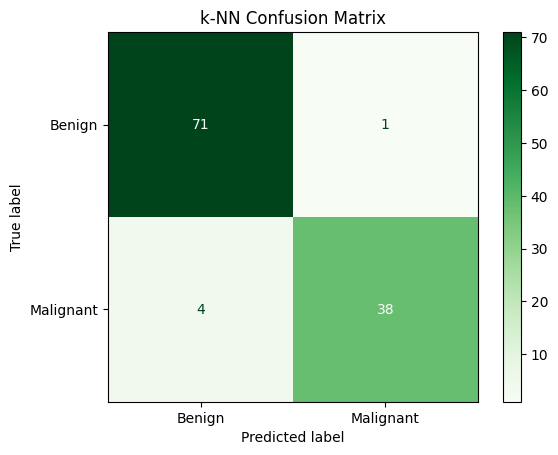

In [75]:
kNeighborDisplay = ConfusionMatrixDisplay(
    confusion_matrix = kNeighborMatrix,
    display_labels = ["Benign", "Malignant"]
)

kNeighborDisplay.plot(cmap = "Greens")

plt.title("k-NN Confusion Matrix")
plt.show()

# Visualizations

The first four cells are all ROC Curve visualizations for each algorithm.

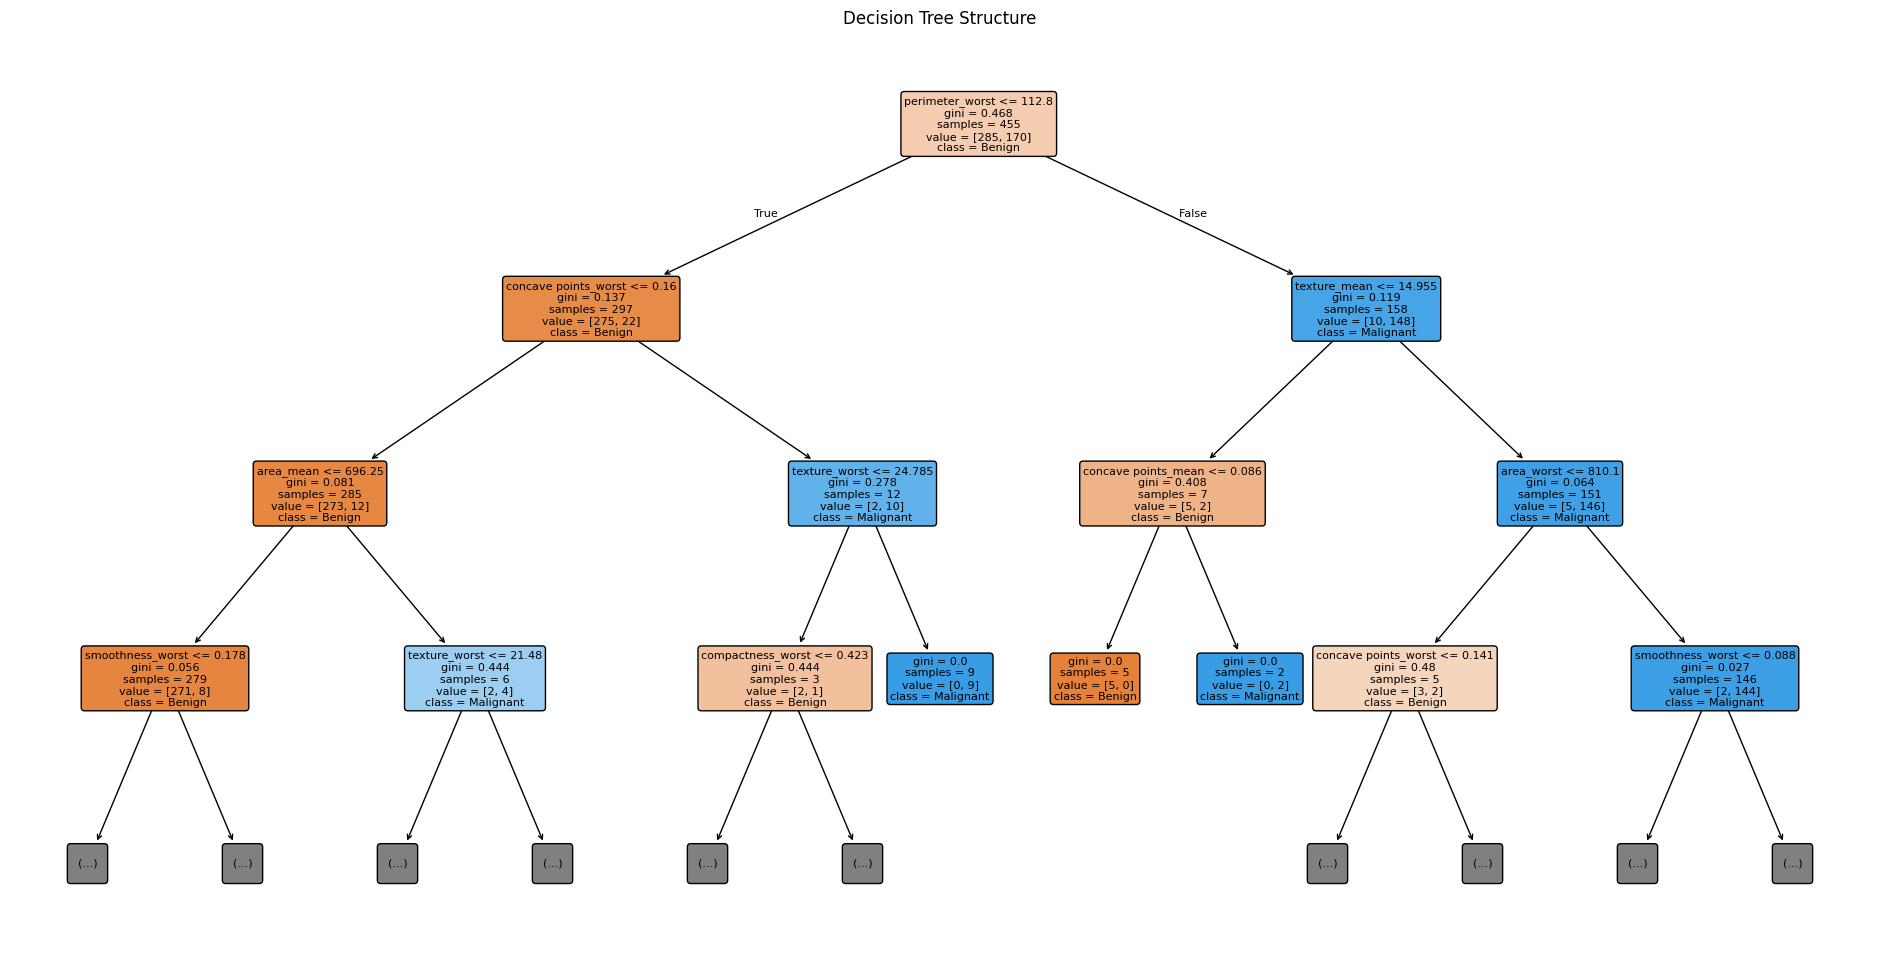

In [76]:
#Showcasing the Decision Tree structure

plt.figure(figsize=(24, 12))

plot_tree(
    decisionTreeModel,
    feature_names=X.columns,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Structure")
plt.show()

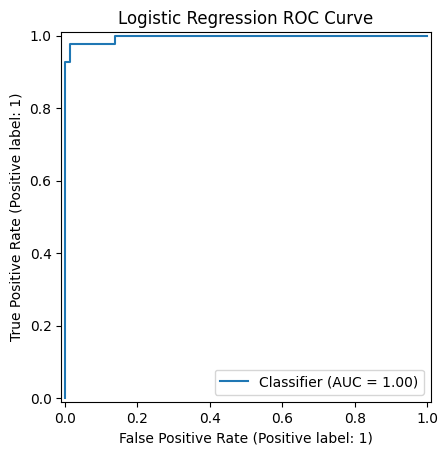

ROC-AUC Score: 0.996031746031746


In [77]:
logisticProbability = logisticModel.predict_proba(XTestScaled)[:, 1]

logisticRocAuc = roc_auc_score(yTest, logisticProbability)

RocCurveDisplay.from_predictions(yTest, logisticProbability)

plt.title("Logistic Regression ROC Curve")
plt.show()

print("ROC-AUC Score:", logisticRocAuc)

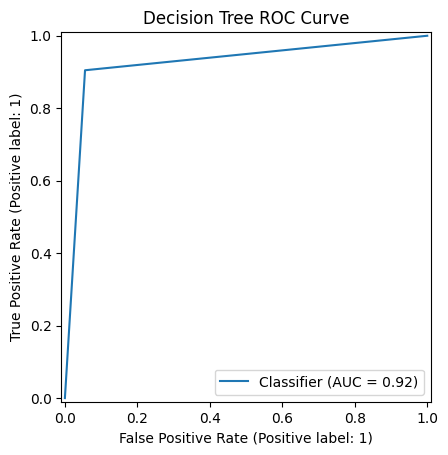

ROC-AUC Score: 0.9246031746031745


In [78]:
decisionTreeProbability = decisionTreeModel.predict_proba(XTest)[:, 1]

decisionTreeRocAuc = roc_auc_score(yTest, decisionTreeProbability)

RocCurveDisplay.from_predictions(yTest, decisionTreeProbability)

plt.title("Decision Tree ROC Curve")
plt.show()

print("ROC-AUC Score:", decisionTreeRocAuc)

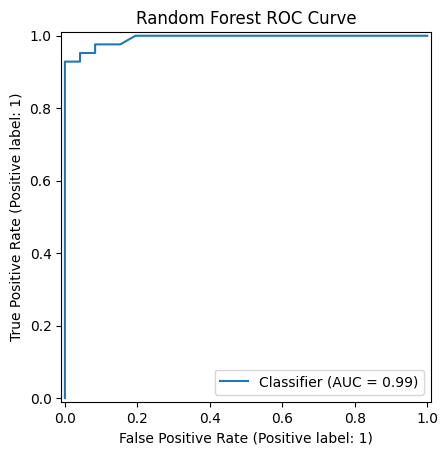

ROC-AUC Score: 0.9928902116402116


In [79]:
randomForestProbability = randomForestModel.predict_proba(XTest)[:, 1]

randomForestRocAuc = roc_auc_score(yTest, randomForestProbability)

RocCurveDisplay.from_predictions(yTest, randomForestProbability)

plt.title("Random Forest ROC Curve")
plt.show()

print("ROC-AUC Score:", randomForestRocAuc)

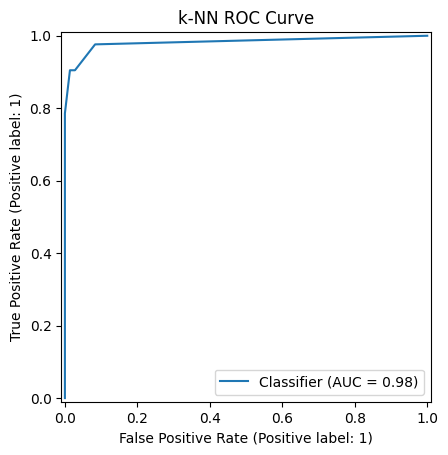

ROC-AUC Score: 0.982308201058201


In [80]:
kNeighborProbability = kNeighborModel.predict_proba(XTestScaled)[:, 1]

kNeighborRocAuc = roc_auc_score(yTest, kNeighborProbability)

RocCurveDisplay.from_predictions(yTest, kNeighborProbability)

plt.title("k-NN ROC Curve")
plt.show()

print("ROC-AUC Score:", kNeighborRocAuc)

The final few cells are all for Precision-Recall curves

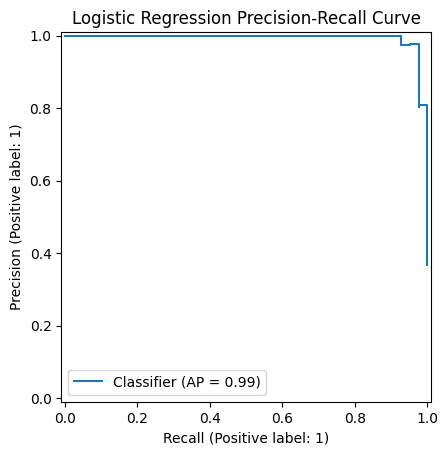

Average Precision Score: 0.994273631904294


In [81]:
logisticProbability = logisticModel.predict_proba(XTestScaled)[:, 1]

logisticPrecisionAuc = average_precision_score(yTest, logisticProbability)

PrecisionRecallDisplay.from_predictions(yTest, logisticProbability)

plt.title("Logistic Regression Precision-Recall Curve")
plt.show()

print("Average Precision Score:", logisticPrecisionAuc)

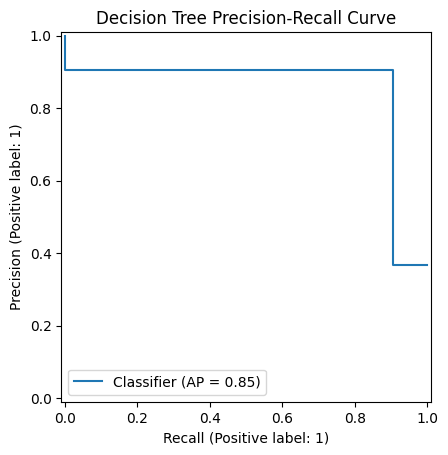

Average Precision Score: 0.8536818236066357


In [82]:
decisionTreeProbability = decisionTreeModel.predict_proba(XTest)[:, 1]

decisionTreePrecisionAuc = average_precision_score(yTest, decisionTreeProbability)

PrecisionRecallDisplay.from_predictions(yTest, decisionTreeProbability)

plt.title("Decision Tree Precision-Recall Curve")
plt.show()

print("Average Precision Score:", decisionTreePrecisionAuc)

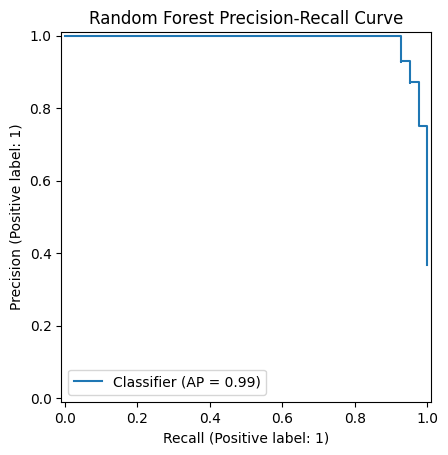

Average Precision Score: 0.9893469758017013


In [83]:
randomForestProbability = randomForestModel.predict_proba(XTest)[:, 1]

randomForestPrecisionAuc = average_precision_score(yTest, randomForestProbability)

PrecisionRecallDisplay.from_predictions(yTest, randomForestProbability)

plt.title("Random Forest Precision-Recall Curve")
plt.show()

print("Average Precision Score:", randomForestPrecisionAuc)

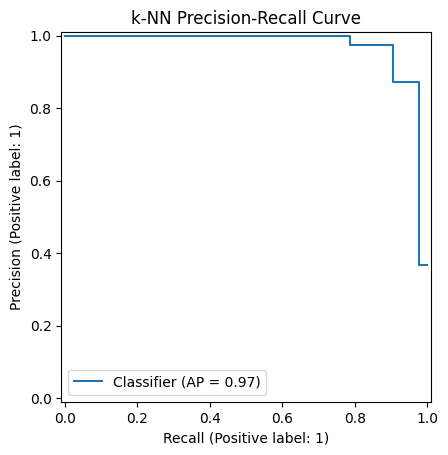

Average Precision Score: 0.9727913619290999


In [84]:
kNeighborProbability = kNeighborModel.predict_proba(XTestScaled)[:, 1]

kNeighborPrecisionAuc = average_precision_score(yTest, kNeighborProbability)

PrecisionRecallDisplay.from_predictions(yTest, kNeighborProbability)

plt.title("k-NN Precision-Recall Curve")
plt.show()

print("Average Precision Score:", kNeighborPrecisionAuc)

# Written Summary

The reason I decided to run four algorithms was because the task requirements said "at least one", which meant I could apply more than one. After looking for a dataset with the help of ChatGPT, I wanted to only apply Logistic Regression, which is why I managed to get the Breast Cancer Wisconsin dataset, which just so happens to fit the bill for the other algorithms I applied. As this is a Classification task, I decided to just apply four of the five algorithms mentioned in the task, the only one unapplied is SVM. Breast Cancer Wisconsin has a total of 569 records and 17 features, has a class imbalance of Benign and Malignant, and fits every requirement listed in the assessment brief. 

To quickly explain the preprocessing stage, I first had to remove the ID column, which was unneeded for calculating classes, and an unnamed column numbered 32, as it was for some reason included in the dataset. I then checked the number of records, aligning which ones were Benign and Malignant, then separated the data between the independent variables and the target variable being diagnoses. Data splitting went smoothly, the total records being 455 for training data, and 114 for testing data, following the 80:20 ratio and the randomizer applied to the splitting process.

The next is the visualizations and algorithm testing. I had to implement different showcases for each algorithm like Logistic Regression's coefficients and the Decision Tree visualization, purely so I could get some extra effort in. This wasn't part of the actual task, but I decided to add them in to have more validations for those algorithms and improve the evidence behind the results made. Apart from this, I followed every other requirement to the letter, meaning the ROC curve, Precision-Recall curve, Confusion Matrix, etc.